##### Проверка работоспособности

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cupy as cp
import numpy as np
import matplotlib.pyplot as plt
from qubo_lib.problems import TSP, MaxCut, RandomQUBO, Just_Q
from qubo_lib.solvers import QBF, QB_F1, BnB, MSSA, Parallel

arr = cp.array([1, 2, 3])
arr2 = cp.array([1, 2, 3])
print(np.sqrt((arr - arr2)**3))
dev_cnt = cp.cuda.runtime.getDeviceCount()
print(f"GPUs available: {dev_cnt}")

[0. 0. 0.]
GPUs available: 2


# Оглавление

### Точные солверы
#### Брутфорсер QBF (https://arxiv.org/pdf/2607.04857)
[на CPU, N=25 (задача коммивояжера, 5 городов)](#QBF_cell_0)  
[на одной GPU, N=36 (задача коммивояжера, 6 городов)](#QBF_cell_1)  
[Та же задача на двух GPU (параллелизм редуцированием на подзадачи)](#QBF_cell_2)  
[на CPU в 8 потоков, та же задача](#QBF_cell_3)  
#### Быстрый брутфорсер QB_F1, только int16, только GPU
[на одной GPU, N=44, случайная матрица](#QB_F1_cell_1)  
[на двух GPU, та же задача](#QB_F1_cell_2)  
#### Метод ветвей и границ, BnB, только CPU, все задачи решаются в 8 потоков
[Задача коммивояжера, N=36, время решения 0.1 сек](#BNB_cell_1)  
[Случайная матрица, N=36, время 63 сек. Плотность матрицы влияет на время](#BNB_cell_2)  
[Матрица с другими случайными значениями (N=36), это тоже влияет на время, время 14 сек. ](#BNB_cell_3)  

### Эвристические солверы
#### Имитация отжига (simulated annealing) MSSA, только GPU
[N = 2500 (задача коммивояжера, 50 городов), параметры по умолчанию, одна GPU](#MSSA_cell_1)  
[Та же задача, меньше семплов, вручную задаем температурный режим](#MSSA_cell_2)  
[Та же задача, автоматически подбираем температурный режим, решаем](#MSSA_cell_3)  
[Та же задача, те же параметры, на двух GPU, параллелизм по семплам](#MSSA_cell_4)  


### Встроенные классы задач
#### Задача коммивояжера (Traveling Salesman Problem), TSP
[Случайная задача коммивояжера, 7 городов, N = 49](#TSP_cell_1)  
[Задача коммивояжера с явно заданными городами, N = 25](#TSP_cell_2)  
[TSP умеет находить хороший путь с помощью ORTools и использовать его как хорошее приближение ground E ](#TSP_cell_3)  
#### Задача максимального разреза графа, MaxCut
[Популярный бенчмарк, граф G22, N = 2000, лучшее решение E = -13359](#MaxCut_cell_1)
#### Случайная QUBO-задача, RandomQUBO
[N = 37, seed = 42, униформное распределение, параметры по умолчанию](#Random_cell_1)
#### Произвольная QUBO-задача, Just_Q
[Обертка для произвольной заданной QUBO-матрицы, N = 99](#Custom_cell_1)

## Точные солверы

##### Брутфорс, QBF() на CPU
<a id='QBF_cell_0'></a>

In [2]:
from qubo_lib.problems import TSP
from qubo_lib.solvers import QBF

# Задача коммивояжера, 5 случайных городов
tsp_problem = TSP.init_random_instance(n_cities = 5, seed = 42) 

# Создадим брутфорс-солвер, QBF это QUBO bruteforce
solver = QBF()

# Решаем задачу брутфорсом на CPU
solution = solver.solve(tsp_problem) 
print(solution)

Solution(
  N=25,
  best_E=-713.532,
  time_to_solve_ms=64.9,
  samples_cnt=1,
  solver_class='QBF',
  best_X='0010000010100000000101000'
)


##### Брутфорс, QBF() на одной GPU
<a id='QBF_cell_1'></a>

In [3]:
# Возьмем задачу побольше, решим тем же солвером, брутфорсом, но уже на видеокарте
# Тут требуется время на прогрев - компиляцию cuda-ядер
tsp_36_bits = TSP.init_random_instance(n_cities = 6, seed = 42) 
solution = solver.solve(tsp_36_bits, device = 'cuda')
print(solution)

Solution(
  N=36,
  best_E=-882.774,
  time_to_solve_ms=1697.3,
  samples_cnt=1,
  solver_class='QBF',
  best_X='100000010000000010001000000001000100'
)


##### Брутфорс, QBF() на двух GPU
<a id='QBF_cell_2'></a>

In [4]:
# Можем распараллелить на 2 видеокарты, 
# Parallel обеспечивает запуск на нескольких устройствах
from qubo_lib.solvers import Parallel

# QBF - солвер, экземпляр которого будет работать на каждом из устройств
solver = Parallel(base_solver=QBF, splits_cnt=2, devices=['cuda'] * 2)
solution = solver.solve(tsp_36_bits)
print(solution)

Solution(
  N=36,
  best_E=-882.771,
  time_to_solve_ms=1400.5,
  samples_cnt=1,
  solver_class='QBF',
  best_X='100000010000000010001000000001000100'
)


##### Брутфорс, QBF(), на CPU в 8 потоков
<a id='QBF_cell_3'></a>

In [5]:
# Можем распараллелить в несколько потоков на CPU
from qubo_lib.solvers import Parallel
solver = Parallel(base_solver=QBF, splits_cnt=8, devices=['cpu'] * 8)
solution = solver.solve(tsp_36_bits)
print(solution)

Solution(
  N=36,
  best_E=-882.774,
  time_to_solve_ms=17915.2,
  samples_cnt=1,
  solver_class='QBF',
  best_X='100000010000000010001000000001000100'
)


##### Очень быстрый брутфорс QB_F1 на GPU, только для типа int16
<a id='QB_F1_cell_1'></a>

In [6]:
import numpy as np
from qubo_lib.solvers import QB_F1, Parallel
from qubo_lib.problems import RandomQUBO
# Еще один класс задач, случайная QUBO-матрица
problem = RandomQUBO.init_random_instance(N=44, seed=42, dtype=np.int16)
solver = QB_F1()
# Тут укажем на какой именно видеокарте запустить
solution_qbf1 = solver.solve(problem, device='cuda:1')
print(solution_qbf1)

Solution(
  N=44,
  best_E=-6902.000,
  time_to_solve_ms=20451.7,
  samples_cnt=1,
  solver_class='QB_F1',
  best_X='10100001111001000111110111111001101111011011'
)


##### QB_F1 на двух GPU
<a id='QB_F1_cell_2'></a>

In [7]:
# Параллельно тоже запускается
solver = Parallel(base_solver=QB_F1, splits_cnt=2, devices=['cuda'] * 2)
solution = solver.solve(problem)
print(solution)

Solution(
  N=44,
  best_E=-6902.000,
  time_to_solve_ms=8990.3,
  samples_cnt=1,
  solver_class='QB_F1',
  best_X='10100001111001000111110111111001101111011011'
)


#### Branch and Bound солвер
<a id='BNB_cell_1'></a>

In [8]:
from qubo_lib.solvers import BnB
tsp_36_bits = TSP.init_random_instance(n_cities = 6, seed = 42) 
solver = BnB()
solution = solver.solve(tsp_36_bits, split_depth = 5, num_threads = 8)
print(solution)

Solution(
  N=36,
  best_E=-882.771,
  time_to_solve_ms=103.4,
  samples_cnt=1,
  solver_class='BnB',
  best_X='000001000010010000000100100000001000'
)


<a id='BNB_cell_2'></a>

In [9]:
# Считает долго, около минуты
problem = RandomQUBO.init_random_instance(N=36, seed=42)
solver = BnB()
solution = solver.solve(problem, split_depth = 5, num_threads = 8)
print(solution)

Solution(
  N=36,
  best_E=-4044.634,
  time_to_solve_ms=63142.9,
  samples_cnt=1,
  solver_class='BnB',
  best_X='001111110111111100100001111111001010'
)


<a id='BNB_cell_3'></a>

In [10]:
problem = RandomQUBO.init_random_instance(N=36, seed=43)
solver = BnB()
solution = solver.solve(problem, split_depth = 5, num_threads = 8)
print(solution)

Solution(
  N=36,
  best_E=-4644.709,
  time_to_solve_ms=14195.2,
  samples_cnt=1,
  solver_class='BnB',
  best_X='111100000111011101010001010101011101'
)


#### MSSA солвер - алгоритм Simulated Annealing на GPU
<a id='MSSA_cell_1'></a>

In [11]:
# Это другой класс солвера
from qubo_lib.solvers import MSSA
from qubo_lib.problems import TSP
solver = MSSA()

# Возьмем побольше городов 
tsp_50 = TSP.init_random_instance(n_cities = 50, seed = 42) 

# Решать будет пару минут, по умолчанию задается 10**7 итераций SA
solution_default = solver.solve(tsp_50) 
print(solution_default)

Solution(
  N=2500,
  best_E=-10918.479,
  time_to_solve_ms=97924.6,
  samples_cnt=200,
  solver_class='MSSA',
  best_X='100000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000100000000000000000000000100000000000000000000000000000000000000001000000000000000000000000000000000000000000000010000000000000000000000000000000000000000000000000000000000010000000000000000000000000000000000000000010000000000000000000000000000000000000000000000000000000000000000000000000000001000000000000000000000000000000000000000000000000100000000000000000000000000000000000000000000000000000000000100000000000000000000000000000000001000000000000000000000000000000000000000000000100000000000000000000000000100000000000000000000000000000000000000000000000000000000000000000000000000000000000010000000000000000000000000000010000000000000000000000000000000000000000000000000000000000100000000000000000000000000000000000000000000001000000000000000000000000000000000000000000000100000

<a id='MSSA_cell_2'></a>

In [12]:
# Метод MSSA.solve принимает такие аргументы
# def solve(self, problem: ProblemABC, samples_cnt=200, epochs_cnt=10, iters_per_epoch=10 ** 6, T=25, rand_seed=42, **kwargs) -> Solution:
    # :param samples_cnt: Number of simultaneous running SA samples. Multistarts
    # :param epochs_cnt: Number of temperature epochs, aka temperature schedule size
    # :param iters_per_epoch: SA iterations per one schedule epoch
    # :param T: Temperature schedule. Can be None, scalar, or np.ndarray epochs_cnt size
        # None value run automatic define T_init and T_final, and make T schedule as geomspace(T_init, T_final, epochs_cnt)
# Решать будет быстрее, потому что задано значительно меньшее число итераций SA

T_sched = np.geomspace(25, 0.1, num=500)
solver = MSSA()
solution_manual_t = solver.solve(tsp_50, samples_cnt = 300, epochs_cnt = 500, iters_per_epoch = 1001, rand_seed = 0, T = T_sched)
print(solution_manual_t)

Solution(
  N=2500,
  best_E=-11178.027,
  time_to_solve_ms=11791.0,
  samples_cnt=300,
  solver_class='MSSA',
  best_X='100000000000000000000000000000000000000000000000000000000000000010000000000000000000000000000000000000000000000000000000000000000000000000000100000000000000000000000000000000000000100000000000000000000000000000000000000000000000000000000100000000000000000000000000000000000000000000000000001000000000000000000000000010000000000000000000000000000000000000010000000000000000000000000000000000000000000001000000000000000000000000000000000000000000000000000000000000000000000000000010000000000000000000000000000000000000000000000001000000000000000000000000000000000000000000000000000000000000000000100000001000000000000000000000000000000000000000000000000000000000000000000000000100000000000000000000000000000000000000000000000000000000000000100000000000000000000000000100000000000000000000000000000000000000000000000000000000000000000000010000000000000000001000000000000000000000000

<a id='MSSA_cell_3'></a>

In [13]:
# T = None run automatic define T_init and T_final, and make T schedule as geomspace(T_init, T_final, epochs_cnt)
# Сперва посмотрим, какие температуры предложит автоматический подбор:
a, b = 0.5, 0.001 # Дефолтные вероятности флипа вверх в начале и в конце отжига
Q = tsp_50.build_Q_matrix()
T_range = MSSA.get_temperature_range(Q, a = a, b = b)
print(f'T_init = {T_range[0]:.1f}; T_final = {T_range[-1]:.3f}')

# Решим 
solution_auto_t = solver.solve(tsp_50, samples_cnt = 300, epochs_cnt = 500, iters_per_epoch = 1001, T = None)
print(solution_auto_t)

T_init = 40564.1; T_final = 0.097
Solution(
  N=2500,
  best_E=-11204.915,
  time_to_solve_ms=14156.2,
  samples_cnt=300,
  solver_class='MSSA',
  best_X='10000000000000000000000000000000000000000000000000000000000000000000000000000000000100000000000000000000000000000100000000000000000000000000000000000000000000000000000000000000000000000010000000000000000000000000000000000000001000000000000000000000000000000001000000000000000000000000000000000000000000000000000000000000000000000000000000010000000000000000000000000010000000000000000000000000000000000000001000000000000000000000000000000000000000000000000000000000000000000000000000100000000000000000000010000000000000000000000000000000000000000000000000000000000000000000000000000000010000000000000000000100000000000000000000000000000000000000000000000000000000000000000000000000000000000000000001000000000000100000000000000000000000000000000000000000000000000000000010000000000000000000000000000000000000000000000000000000000000000000000001000

<a id='MSSA_cell_4'></a>

In [14]:
# MSSA можно запустить параллельно на нескольких GPU. Деления задачи на подзадачи не происходит
from qubo_lib.solvers import Parallel, MSSA
parallel_solver = Parallel(base_solver=MSSA, splits_cnt=2, devices=['cuda']*2)

# Общее число семплов total_samples_cnt = 500 будет поделено на splits_cnt=2 частей
solution_50 = parallel_solver.solve(tsp_50, total_samples_cnt = 300, epochs_cnt = 500, iters_per_epoch = 1001, T = None)
print(solution_50)

Solution(
  N=2500,
  best_E=-11211.395,
  time_to_solve_ms=9616.9,
  samples_cnt=300,
  solver_class='MSSA',
  best_X='1000000000000000000000000000000000000000000000000000000000010000000000000000000000000000000000000000000000000000000000000000000001000000000000000000000000000000000000000000001000000000000000000000000000000000000000000000000000000000000010000000000000000000000000000000000000000100000000000000000000000000000000001000000000000000000000000000000000000000000000000000000000000000000000000000000000001000000000000000000000000000000000000000000001000000000000000000100000000000000000000000000000000000000000000000100000000000000000000000000000000000000000000000000000000000000010000000000000000000000000000000000000000000000000000000000000000000100000000000000000000000000000000000000000000000000010000000000000000000000000000000001000000000000000000000000000000000000100000000000000000000000000000000000000000000000000000000000000000000010000000000000000000000000000000000000000000000

### Демо разных классов задач

##### Задача коммивояжера - Traveling Salesman Problem - TSP
<a id='TSP_cell_1'></a>

In [15]:
# Создадим случайную задачу TSP на 7 городов
tsp_problem = TSP.init_random_instance(n_cities = 7, seed = 42) 

In [16]:
# Просто посмотрим какие города выдал рандом
tsp_problem.cities

array([[77.39561 , 43.887844],
       [85.859795, 69.7368  ],
       [ 9.417735, 97.56223 ],
       [76.11397 , 78.60643 ],
       [12.811363, 45.038593],
       [37.079803, 92.6765  ],
       [64.38651 , 82.27616 ]], dtype=float32)

In [17]:
import numpy as np
import matplotlib.pyplot as plt
# И какая по ним была построена QUBO-матрица
Q = tsp_problem.build_Q_matrix()
print(np.round(Q[:10, :10]))
print(Q.shape)

[[-174.  348.  348.  348.  348.  348.  348.  348.   27.    0.]
 [   0. -174.  348.  348.  348.  348.  348.   27.  348.   27.]
 [   0.    0. -174.  348.  348.  348.  348.    0.   27.  348.]
 [   0.    0.    0. -174.  348.  348.  348.    0.    0.   27.]
 [   0.    0.    0.    0. -174.  348.  348.    0.    0.    0.]
 [   0.    0.    0.    0.    0. -174.  348.    0.    0.    0.]
 [   0.    0.    0.    0.    0.    0. -174.    0.    0.    0.]
 [   0.    0.    0.    0.    0.    0.    0. -174.  348.  348.]
 [   0.    0.    0.    0.    0.    0.    0.    0. -174.  348.]
 [   0.    0.    0.    0.    0.    0.    0.    0.    0. -174.]]
(49, 49)


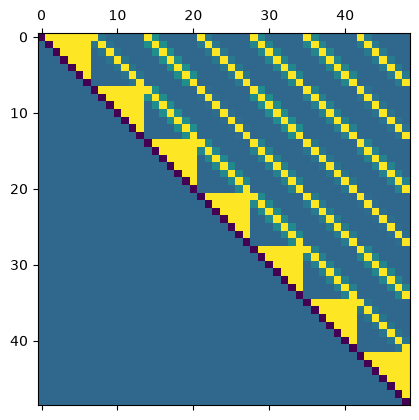

In [18]:
_ = plt.matshow(Q)

<a id='TSP_cell_2'></a>

[[-134.  269.  269.  269.  269.  269.   14.    0.    0.    0.]
 [   0. -134.  269.  269.  269.   14.  269.   14.    0.    0.]
 [   0.    0. -134.  269.  269.    0.   14.  269.   14.    0.]
 [   0.    0.    0. -134.  269.    0.    0.   14.  269.   14.]
 [   0.    0.    0.    0. -134.    0.    0.    0.   14.  269.]
 [   0.    0.    0.    0.    0. -134.  269.  269.  269.  269.]
 [   0.    0.    0.    0.    0.    0. -134.  269.  269.  269.]
 [   0.    0.    0.    0.    0.    0.    0. -134.  269.  269.]
 [   0.    0.    0.    0.    0.    0.    0.    0. -134.  269.]
 [   0.    0.    0.    0.    0.    0.    0.    0.    0. -134.]]
(25, 25)


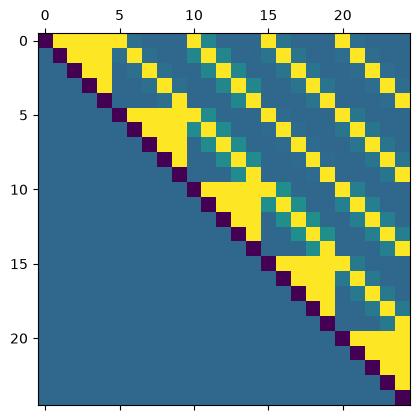

In [19]:
# Координаты городов можно задать явно
tsp5 = TSP.init_from_cities(np.array([(10, 40), (20, 30), (10, 90), (25, 25), (10, 50)]))
Q = tsp5.build_Q_matrix()
print(np.round(Q[:10, :10]))
print(Q.shape)
_ = plt.matshow(Q)

<a id='TSP_cell_3'></a>

In [20]:
# Решим задачу TSP на 50 городов с помощью MSSA, и сравним найденное решение с приближенеим ground state

tsp_50 = TSP.init_random_instance(n_cities = 50, seed = 42) 
tsp_50.calculate_ground()
parallel_solver = Parallel(base_solver=MSSA, splits_cnt=2, devices=['cuda']*2)
solution_50 = parallel_solver.solve(tsp_50, total_samples_cnt = 300, epochs_cnt = 500, iters_per_epoch = 1001, T = None)
    
print(f'Энергия MSSA: {solution_50.best_E:.2f}')
print(f'Граунд:       {tsp_50.ground_E:.2f}')

Энергия MSSA: -11211.39
Граунд:       -11942.17


##### MaxCut - задача максимального разреза графа
https://ru.wikipedia.org/wiki/%D0%9C%D0%B0%D0%BA%D1%81%D0%B8%D0%BC%D0%B0%D0%BB%D1%8C%D0%BD%D1%8B%D0%B9_%D1%80%D0%B0%D0%B7%D1%80%D0%B5%D0%B7_%D0%B3%D1%80%D0%B0%D1%84%D0%B0

MaxCut - очень популярный бенчмарк для различных методов дискретной оптимизации.   
Поддерживается база именованных графов, и лучших известных решений на них
<a id='MaxCut_cell_1'></a>

In [21]:
from qubo_lib.problems import MaxCut
# Создаем граф G22 из стандартного набора maxcut-графов 
g22 = MaxCut('G22')
# Число неизвестных в QUBO-формулировке задачи MaxCut совпадает с числом вершин в графе 
print(f"Число вершин в графе: {g22.N}")
# Посмотрим лучшее известное решение для него, точнее его энергию в QUBO-формулировке
print(f"Лучшее известное решение: {g22.ground_E}")

Число вершин в графе: 2000
Лучшее известное решение: -13359


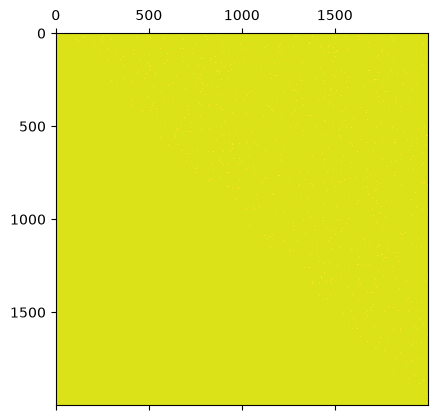

In [22]:
Q = g22.build_Q_matrix()
_ = plt.matshow(Q)

In [23]:
# Посмотрим как справится с этой задачей MSSA-солвер
##### Работает в контейнере на платформе cloud.ru
solver = MSSA()
T_sched = np.geomspace(2.5, 0.1, num=500)
solution = solver.solve(g22, samples_cnt = 10, epochs_cnt = 500, iters_per_epoch = 1001, T = T_sched)
print(f"Лучшее известное решение: {g22.ground_E}")
print(f"Решение найденное MSSA: {solution.best_E}")
print(f"Время решения, мсек: {solution.time_to_solve_ms:.1f}")

Лучшее известное решение: -13359
Решение найденное MSSA: -13358.0
Время решения, мсек: 3770.9


In [24]:
# Неплохо

##### Случайная QUBO-задача
<a id='Random_cell_1'></a>

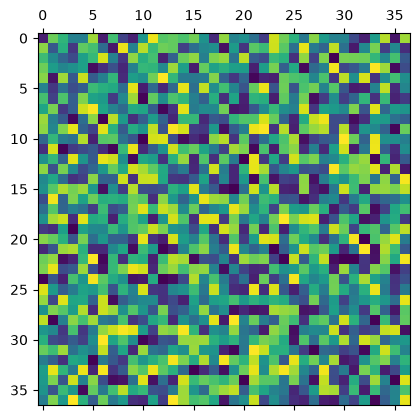

In [25]:
from qubo_lib.problems import RandomQUBO
rnd_problem = RandomQUBO.init_random_instance(seed = 42, N = 37)
Q = rnd_problem.build_Q_matrix()
_ = plt.matshow(Q)

In [26]:
# Решим брутфорсом на ЦПУ, будет долго, минуту
solver = QBF()
solution = solver.solve(rnd_problem)
print(solution)

Solution(
  N=37,
  best_E=-4251.896,
  time_to_solve_ms=115689.9,
  samples_cnt=1,
  solver_class='QBF',
  best_X='0101011110011001001010000111101110111'
)


In [27]:
# А теперь решим ее на видеокарте, должно быть быстрее
solver = QBF()
solution_1_gpu = solver.solve(rnd_problem, device = 'cuda')

# На двух видеокартах, будет еще быстрее
solver = Parallel(base_solver=QBF, splits_cnt=2, devices=['cuda'] * 2)
solution_2_gpu = solver.solve(rnd_problem)

print(f"Время решения на CPU, мсек: {solution.time_to_solve_ms}")
print(f"Время решения на одной GPU, мсек: {solution_1_gpu.time_to_solve_ms}")
print(f"Время решения на двух GPU, мсек: {solution_2_gpu.time_to_solve_ms}")

Время решения на CPU, мсек: 115689.91558579728
Время решения на одной GPU, мсек: 3263.611674785614
Время решения на двух GPU, мсек: 2692.9171794354916


##### Кастомная QUBO-задача
<a id='Custom_cell_1'></a>

In [28]:
# Допустим нам нужно решить QUBO-задачу, которая не включена в библиотеку
# Построим кубо-матрицу для этой задачи
n = 99
matrix = np.zeros((n, n))
c1 = 0.5, 0.5
c2 = 0.3, 0.8
for i in range(n):
    for j in range(n):
        x, y = i/n, j/n
        d1 = np.sqrt((x - c1[0])**2 + (y - c1[1])**2)
        d2 = np.sqrt((x - c2[0])**2 + (y - c2[1])**2)
        wave1 = np.sin(d1*50) * np.exp(-d1)
        wave2 = np.sin(d2*10+0.3) * np.exp(-d2)
        matrix[i, j] = wave1 + 2*wave2

In [29]:
# Теперь обернем эту матрицу в класс Just_Q и решим задачу на ней
from qubo_lib.problems import Just_Q
problem = Just_Q(matrix)
solver = MSSA()
solution = solver.solve(problem, iters_per_epoch=3*10**5)
print(solution)

Solution(
  N=99,
  best_E=-1138.629,
  time_to_solve_ms=3963.3,
  samples_cnt=200,
  solver_class='MSSA',
  best_X='001111000000000111110000011111111111111111111111111111111111110000000000000000000000000000000000000'
)


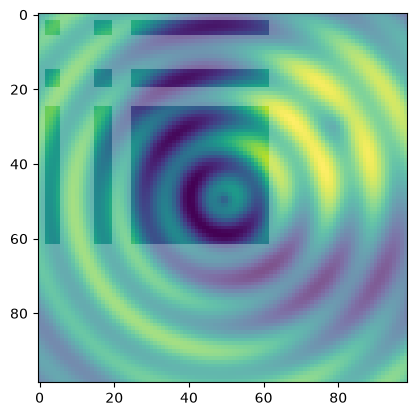

In [30]:
mask = np.array([int(bit) for bit in solution.best_X])
alpha_matrix = np.outer(mask, mask).astype(float)
alpha_matrix[alpha_matrix == 0] = 0.7
alpha_matrix[alpha_matrix == 1] = 1.0

im = plt.imshow(matrix, alpha=alpha_matrix, interpolation='nearest')
    
plt.show()